<a href="https://colab.research.google.com/github/MariaFeledi-cesar/RNA-e-Deep-Learning-CESAR-School-2026.01-A/blob/main/Atividade%202/atividade_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Dataset — California Housing

A base possui **20.640 registros e 8 variáveis de entrada**, que serão utilizadas para prever o valor mediano das casas.

**Variáveis de entrada (`X`):**
- `MedInc`: renda mediana dos moradores.
- `HouseAge`: idade mediana das casas.
- `AveRooms`: média de cômodos por residência.
- `AveBedrms`: média de quartos por residência.
- `Population`: população do quarteirão.
- `AveOccup`: média de moradores por residência.
- `Latitude`: latitude.
- `Longitude`: longitude.

**Variável de saída (`y`):**
- `MedHouseVal`: valor mediano das casas, expresso em centenas de milhares de dólares.

## 1 - Importação das bibliotecas

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error

import torch
import torch.nn as nn
import torch.optim as optim

## 2 - Importação e leitura dos dados

In [2]:
# Carregar o dataset
dados = fetch_california_housing(as_frame=True)

# Separar as variáveis de entrada e saída
X = dados.data
y = dados.target

# Visualizar as primeiras linhas
display(X.head())

# Visualizar os primeiros valores da variável de saída
display(y.head())

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25


,MedHouseVal
0,4.526
1,3.585
2,3.521
3,3.413
4,3.422


In [3]:
print('Dimensões de X:', X.shape)
print('Dimensões de y:', y.shape)

Dimensões de X: (20640, 8)
Dimensões de y: (20640,)


In [5]:
# Estatísticas descritivas das variáveis
display(X.describe())

# Estatísticas descritivas do preço
display(y.describe())

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000


,MedHouseVal
count,20640.000000
mean,2.068558
std,1.153956
min,0.149990
25%,1.196000
50%,1.797000
75%,2.647250
max,5.000010


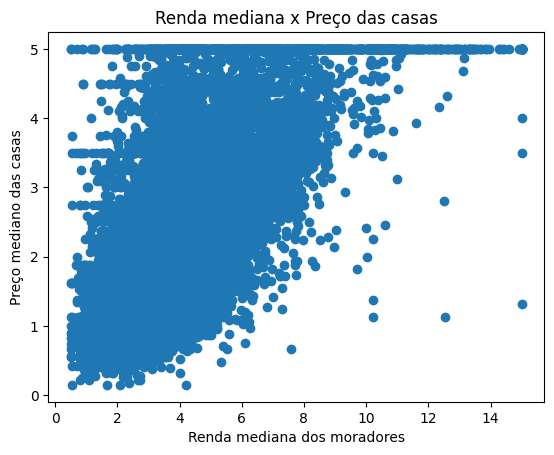

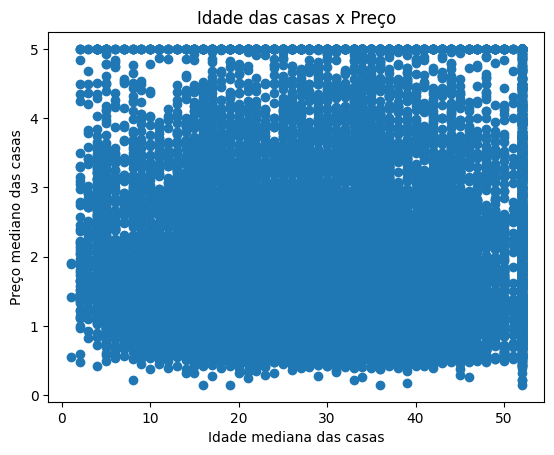

In [4]:
# Gráfico 1: renda mediana x preço das casas
plt.scatter(X['MedInc'], y)
plt.xlabel('Renda mediana dos moradores')
plt.ylabel('Preço mediano das casas')
plt.title('Renda mediana x Preço das casas')
plt.show()

# Gráfico 2: idade das casas x preço
plt.scatter(X['HouseAge'], y)
plt.xlabel('Idade mediana das casas')
plt.ylabel('Preço mediano das casas')
plt.title('Idade das casas x Preço')
plt.show()

### 2.1 - Análise descritiva e visual dos dados

A base possui **20.640 registros**, sem valores faltantes nas variáveis analisadas.

Pelo `describe()`, observamos que:
- A idade média das casas (`HouseAge`) é de aproximadamente **28,6 anos**.
- A renda mediana (`MedInc`) é de **3,87**.
- A população média por quarteirão é de aproximadamente **1.425 habitantes**.
- O preço mediano das casas (`MedHouseVal`) é de aproximadamente **US$ 206.856**.

**Análise dos gráficos:**

- **Renda x Preço:** apresenta uma tendência positiva. Em geral, quanto maior a renda dos moradores, maior o preço das casas.
- **Idade x Preço:** não apresenta uma relação clara, pois os preços variam bastante independentemente da idade das casas.

Assim, a renda parece ter uma relação mais evidente com o preço dos imóveis do que a idade das casas.

## 3 - Divisão em treino, validação e teste

In [6]:
# Primeira divisão: 70% treino e 30% temporário
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=111
)

# Segunda divisão: 15% validação e 15% teste
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=111
)

In [7]:
print('Treino:', X_train.shape, y_train.shape)
print('Validação:', X_val.shape, y_val.shape)
print('Teste:', X_test.shape, y_test.shape)

Treino: (14448, 8) (14448,)
Validação: (3096, 8) (3096,)
Teste: (3096, 8) (3096,)


## 4 - Normalização

In [8]:
# Ajustar os scalers somente com os dados de treino
x_scaler = StandardScaler().fit(X_train)
y_scaler = StandardScaler().fit(y_train.values.reshape(-1, 1))

# Padronizar os dados e converter para tensores float32
X_train_scaled = torch.from_numpy(x_scaler.transform(X_train)).float()
y_train_scaled = torch.from_numpy(y_scaler.transform(y_train.values.reshape(-1, 1))).float()

X_val_scaled = torch.from_numpy(x_scaler.transform(X_val)).float()
y_val_scaled = torch.from_numpy(y_scaler.transform(y_val.values.reshape(-1, 1))).float()

X_test_scaled = torch.from_numpy(x_scaler.transform(X_test)).float()
y_test_scaled = torch.from_numpy(y_scaler.transform(y_test.values.reshape(-1, 1))).float()

## 5 - Modelo

In [9]:
# Criar o modelo
model = nn.Linear(8, 1)

print('Pesos:', model.weight)
print('Bias:', model.bias)

# Testar o modelo com os três primeiros registros
model(X_train_scaled[:3])

Pesos: Parameter containing:
tensor([[-0.1922, -0.2814,  0.3492,  0.1427, -0.0094, -0.1328, -0.0041,  0.1424]],
       requires_grad=True)
Bias: Parameter containing:
tensor([-0.1805], requires_grad=True)


tensor([[-0.3143],
        [-0.2559],
        [-0.3160]], grad_fn=<AddmmBackward0>)

### 5.1 - Função de custo e otimizador

In [10]:
lr = 0.1

criterion = nn.MSELoss()

optimizer = optim.SGD(model.parameters(), lr=lr)

### 5.2 - Função de treino e de validação

In [11]:
def train_epoch(model, optimizer, criterion, x_train, y_train):
    model.train()
    optimizer.zero_grad()

    # Forward: gerar previsões
    y_pred = model(x_train)
    loss = criterion(y_pred, y_train)

    # Backward: calcular gradientes e atualizar parâmetros
    loss.backward()
    optimizer.step()

    return loss.item()


def validate_epoch(model, criterion, x_val, y_val):
    model.eval()

    with torch.no_grad():
        y_pred = model(x_val)
        loss = criterion(y_pred, y_val)

    return loss.item()

### 5.3 - Laço de treinamento

In [12]:
n_epochs = 120

train_losses = []
val_losses = []

for epoch in range(n_epochs):

    # Treinamento
    train_loss = train_epoch(
        model, optimizer, criterion,
        X_train_scaled, y_train_scaled
    )
    train_losses.append(train_loss)

    # Validação
    val_loss = validate_epoch(
        model, criterion,
        X_val_scaled, y_val_scaled
    )
    val_losses.append(val_loss)

    if (epoch + 1) % 20 == 0:
        print(
            f'Epoch [{epoch + 1}/{n_epochs}], '
            f'Train Loss: {train_loss:.6f}, '
            f'Val Loss: {val_loss:.6f}'
        )

Epoch [20/120], Train Loss: 0.463839, Val Loss: 0.479033
Epoch [40/120], Train Loss: 0.428601, Val Loss: 0.444744
Epoch [60/120], Train Loss: 0.411044, Val Loss: 0.427007
Epoch [80/120], Train Loss: 0.402075, Val Loss: 0.417490
Epoch [100/120], Train Loss: 0.397467, Val Loss: 0.412222
Epoch [120/120], Train Loss: 0.395081, Val Loss: 0.409196


### 5.4 - Curvas de custo de treino e de validação

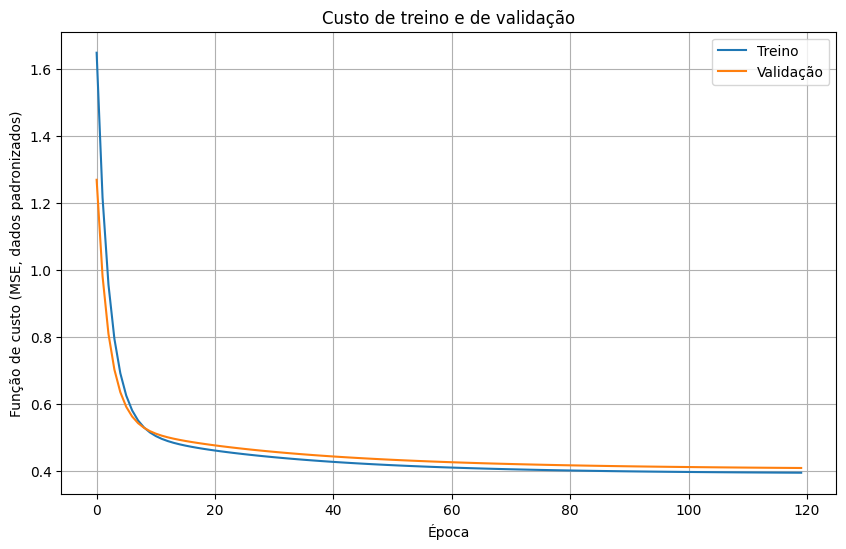

In [13]:
plt.figure(figsize=(10, 6))

plt.plot(range(n_epochs), train_losses, label='Treino')
plt.plot(range(n_epochs), val_losses, label='Validação')

plt.xlabel('Época')
plt.ylabel('Função de custo (MSE, dados padronizados)')
plt.title('Custo de treino e de validação')

plt.legend()
plt.grid(True)
plt.show()

In [14]:
print(f'MSE final treino: {train_losses[-1]:.4f}')
print(f'MSE final validação: {val_losses[-1]:.4f}')

MSE final treino: 0.3951
MSE final validação: 0.4092


### 6 - RMSE no teste em dólares

In [15]:
# Colocar o modelo em modo de avaliação
model.eval()

with torch.no_grad():
    # Gerar previsões na escala padronizada
    y_pred_test_scaled = model(X_test_scaled).cpu().numpy()

# Converter as previsões para a escala original
y_pred_test = y_scaler.inverse_transform(y_pred_test_scaled)

# Converter os valores reais para a escala original
y_test_original = y_test.values.reshape(-1, 1)

In [16]:
# Converter os valores para dólares
y_pred_dollars = y_pred_test * 100000
y_test_dollars = y_test_original * 100000

# Calcular o RMSE
rmse_model = np.sqrt(np.mean((y_pred_dollars - y_test_dollars) ** 2))

print(f'RMSE do modelo: US$ {rmse_model:,.2f}')

RMSE do modelo: US$ 73,911.98


In [17]:
# Calcular a média dos preços do treino
media_treino = y_train.mean()

# Prever sempre a média do treino
y_pred_baseline = np.full(len(y_test), media_treino * 100000)

# Calcular o RMSE do baseline
rmse_baseline = np.sqrt(np.mean((y_pred_baseline - y_test_dollars.ravel()) ** 2))

# Comparar os resultados
print(f'RMSE do modelo:   US$ {rmse_model:,.2f}')
print(f'RMSE do baseline: US$ {rmse_baseline:,.2f}')

RMSE do modelo:   US$ 73,911.98
RMSE do baseline: US$ 116,100.80


#### Análise do RMSE no conjunto de teste

O modelo de regressão linear apresentou RMSE de **US 73.911,98**, enquanto o baseline apresentou **US 116.100,80**.

Isso representa uma redução de aproximadamente **36,3% no erro** em relação ao baseline.

Portanto, o modelo conseguiu utilizar as características dos imóveis para realizar previsões melhores do que simplesmente utilizar o preço médio do conjunto de treino.

### 7 - Analisando os 8 pesos aprendidos

In [18]:
# Extrair os pesos aprendidos pelo modelo
pesos = model.weight.detach().numpy().flatten()

# Associar cada peso à sua variável
df_pesos = pd.DataFrame({
    'Variável': X.columns,
    'Peso': pesos
})

# Ordenar do maior para o menor
df_pesos = df_pesos.sort_values(by='Peso', ascending=False)

display(df_pesos)

,Variável,Peso
0,MedInc,0.732516
3,AveBedrms,0.221803
1,HouseAge,0.121686
4,Population,-0.002849
5,AveOccup,-0.041426
2,AveRooms,-0.214443
7,Longitude,-0.597880
6,Latitude,-0.621585


#### Análise dos pesos aprendidos

- **Variáveis que mais aumentam o preço:**
  - `MedInc` (0,7325): renda mediana dos moradores. Apresenta a maior influência positiva.
  - `AveBedrms` (0,2218): média de quartos por residência.
  - `HouseAge` (0,1217): idade mediana das casas.

- **Variáveis que mais diminuem o preço:**
  - `Latitude` (-0,6216): localização geográfica na direção norte-sul.
  - `Longitude` (-0,5979): localização geográfica na direção leste-oeste.
  - `AveRooms` (-0,2144): média de cômodos por residência.

- **Variáveis com pouca influência:** `Population` (-0,0028), que representa a população do quarteirão, e `AveOccup` (-0,0414), que representa a média de moradores por residência, apresentam pesos próximos de zero.

A comparação entre os pesos só faz sentido porque as variáveis de entrada foram padronizadas com o `StandardScaler`. Dessa forma, todas estão na mesma escala, com média próxima de zero e desvio padrão próximo de um. Assim, podemos comparar a intensidade e a direção da influência de cada variável no preço previsto.

**Observação:** os pesos representam relações aprendidas pelo modelo, não relações de causa e efeito. Além disso, os pesos de latitude e longitude indicam padrões geográficos presentes nos dados, não que essas coordenadas reduzam diretamente o valor dos imóveis.

### 8 - Conclusão

O modelo apresentou um resultado satisfatório, pois conseguiu reduzir o erro em relação ao baseline, mostrando que as características dos imóveis ajudam a estimar seus preços.

As curvas de treino e validação também apresentaram comportamentos próximos, indicando um aprendizado estável.

Apesar do resultado positivo, o RMSE de aproximadamente **US$ 73,9 mil** mostra que ainda existem erros consideráveis nas previsões. Para melhorar o desempenho, eu tentaria testar uma rede neural mais complexa, com mais camadas, e comparar os resultados com outros modelos já estudados, como o Random Forest.

Portanto, o modelo é uma boa primeira abordagem, mas ainda há espaço para melhorias na precisão das previsões.